In [4]:
from adabmDCA.fasta import import_from_fasta, decode_sequence, write_fasta
from adabmDCA.sampling import gibbs_sampling
from adabmDCA.statmech import compute_energy
import adabmDCA as dca
from tqdm.notebook import tqdm

import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import time
import RNA
import torch

from concurrent.futures import ProcessPoolExecutor
from functools import partial

# use latex and font size 14
plt.rc('text', usetex=True)
plt.rc('font', size=14)

tokens = "ACGU-"
dot_bracket_with_pk = "...(((((((..((....)).)))))))...((((((....((((((...((...((((((....))))))..))...))))))(((...(.((((((....)))))).)..)))...[.[[[[[...))))))((((...(((....)))..))))......]]]]]]..((.(((((....))))).....)).."

In [2]:
def compute_bpp_matrix(sequence):
    """
    Compute the base-pairing probability (bpp) matrix via ViennaRNA.

    Parameters
    ----------
    sequence : str
        RNA sequence (T già convertiti in U se presenti gap).

    Returns
    -------
    bpp : np.ndarray, shape (L, L)
        Matrice simmetrica delle probabilità di appaiamento (L = len(sequence)).
    """
    fc = RNA.fold_compound(sequence)
    propensity, ensemble_energy = fc.pf()
    basepair_probs = fc.bpp()  # nested list, 1-based

    L = len(sequence)
    bpp = np.zeros((L, L), dtype=float)
    for i in range(1, L+1):
        for j in range(1, L+1):
            bpp[i-1, j-1] = basepair_probs[i][j]
    return bpp


def dot_bracket_to_ss_matrix(ss):
    """
    Convert a dot-bracket string into a binary contact matrix.

    Parameters
    ----------
    ss : str
        Notazione secondaria “dot-bracket”.

    Returns
    -------
    cm : np.ndarray, shape (L, L)
        Matrice binaria con cm[i,j]=1 se i e j sono appaiati nella struttura.
    """
    L = len(ss)
    cm = np.zeros((L, L), dtype=int)
    stack_round = []  # for (
    stack_square = []  # for [
    stack_angle = []  # for <
    stack_curly = []  # for {
    for pos, c in enumerate(ss):
        if c == '(':
            stack_round.append(pos)
        elif c == '[':
            stack_square.append(pos)
        elif c == '<':
            stack_angle.append(pos)
        elif c == '{':
            stack_curly.append(pos)
        elif c == ')':
            if stack_round:
                i = stack_round.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == ']':
            if stack_square:
                i = stack_square.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == '>':
            if stack_angle:
                i = stack_angle.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == '}':
            if stack_curly:
                i = stack_curly.pop()
                cm[i, pos] = cm[pos, i] = 1
    return cm



def _bpp_score_for_sequence(seq, cm):
    seq = seq.upper().replace('T', 'U')
    bpp = compute_bpp_matrix(seq)
    return float((bpp * cm).sum())

def compute_bpp_scores(sequences_one_hot, dot_bracket, num_workers=4):
    sequences_v = torch.argmax(sequences_one_hot, dim=-1)
    sequences = ["GUG"+ "".join(tokens[i] for i in sequence) + "G" for sequence in sequences_v]

    """
    Compute BPP scores and gap violations for a list of sequences given a dot-bracket structure.

    Args:
        sequences (list of str): List of RNA sequences (strings with 'U' instead of 'T').
        dot_bracket (str): Dot-bracket string representing the structure.
        num_workers (int): Number of processes to parallelize over.

    Returns:
        bpp_scores (list of float): BPP scores for each sequence.
        gap_violations (int): Number of gap violations across all sequences.
    """
    # Convert dot-bracket to structure matrix once
    cm = dot_bracket_to_ss_matrix(dot_bracket)

    # Use process pool to parallelize computation
    with ProcessPoolExecutor(max_workers=num_workers) as executor:
        bpp_scores = list(executor.map(partial(_bpp_score_for_sequence, cm=cm), sequences))

    return bpp_scores

### Import DCA model

In [3]:
# Load model
path_model = "../Group_I_Intron/modello_FC_T=1"
params_np = np.load(path_model)
params = {
    'bias': torch.tensor(params_np['h_local'], dtype=torch.float32, device='cuda').contiguous(),
    'coupling_matrix': torch.tensor(params_np['couplings'], dtype=torch.float32, device='cuda').contiguous()
}

### Import data

In [127]:
path_wt = "../lore/WTs_to_thermo_fix.fasta"
wt_headers, wt_sequences_enc = import_from_fasta(path_wt, tokens=tokens)
wt_sequences_enc = wt_sequences_enc[:, 3:-1]
wt_sequences_oh = torch.nn.functional.one_hot(torch.tensor(wt_sequences_enc), num_classes=len(tokens)).float().to("cuda")
wt_mapping = {header: seq_oh for header, seq_oh in zip(wt_headers, wt_sequences_oh)}

fname_azo = "../Group_I_Intron/azo.seq"
h_azo, s_azo_enc = import_from_fasta(fname_azo, tokens=tokens)
s_azo_oh = torch.nn.functional.one_hot(torch.tensor(s_azo_enc), num_classes=len(tokens)).float().to("cuda")

In [186]:
wt_name = "wt_10"

wt_energy = dca.compute_energy(wt_mapping[wt_name].unsqueeze(0), params).item()
wt_bpp_score = compute_bpp_scores(wt_mapping[wt_name].unsqueeze(0), dot_bracket_with_pk, num_workers=1)[0]

paths_mutants = {
    "lowDCA_lowSB": f"../Experiment_sequences/lowDCA_lowSB/{wt_name}_mutants_lowDCA_lowSB_beta1.25_sb-3.00.fasta",
    "lowDCA_highSB": f"../Experiment_sequences/lowDCA_highSB/{wt_name}_mut_lowDCA_highSB_beta1.5_sb2.0.fasta",
    "highDCA_highSB": f"../Experiment_sequences/highDCA_highSB/{wt_name}_mut_highDCA_highSB_beta0_sb3.9.fasta"
}

In [187]:
df_mutants = pd.DataFrame()
print(f"Wild-type: {wt_name}, DCA energy: {wt_energy:.4f}, BPP score: {wt_bpp_score:.4f}")
for condition, path in paths_mutants.items():
    print(f"Importing mutant sequences {condition}")
    mut_headers, mut_sequences_enc = import_from_fasta(path, tokens=tokens)
    n_initial = len(mut_headers)
    mut_headers, mut_sequences_enc = import_from_fasta(path, tokens=tokens, remove_duplicates=True)
    n_unique = len(mut_headers)
    print(f"---> Initial sequences: {n_initial}, unique sequences: {n_unique}")
    mut_sequences_str = decode_sequence(mut_sequences_enc, tokens)
    mut_sequences_oh = torch.nn.functional.one_hot(torch.tensor(mut_sequences_enc), num_classes=len(tokens)).float().to("cuda")
    mean_seqid, err_seqid = dca.get_seqid_stats(mut_sequences_oh)
    mean_distance = len(mut_sequences_oh[0]) - mean_seqid
    print(f"---> Mean distance between mutants: {mean_distance:.4f} ± {err_seqid:.4f}")
    mut_sequences_oh = torch.nn.functional.one_hot(torch.tensor(mut_sequences_enc), num_classes=len(tokens)).float().to("cuda")
    dca_energies = dca.compute_energy(mut_sequences_oh, params).cpu().numpy()
    bpp_scores = compute_bpp_scores(mut_sequences_oh, dot_bracket_with_pk, num_workers=20)
    distances_from_azo = mut_sequences_oh.shape[1] -dca.get_seqid(mut_sequences_oh, s_azo_oh.squeeze(0)).cpu().numpy()
    print(f"---> Min distance from Azo: {distances_from_azo.min()}, Max distance from Azo: {distances_from_azo.max()}")
    
    df_temp = pd.DataFrame({
        "header": mut_headers,
        "region": condition,
        "dca_energy": dca_energies,
        "bpp_score": bpp_scores,
        "sequence": mut_sequences_str
    })
    df_mutants = pd.concat([df_mutants, df_temp], ignore_index=True)   
    

Wild-type: wt_10, DCA energy: 82.2753, BPP score: 22.2587
Importing mutant sequences lowDCA_lowSB
---> Initial sequences: 1427, unique sequences: 1422
---> Mean distance between mutants: 10.9107 ± 0.0704
---> Min distance from Azo: 25.0, Max distance from Azo: 30.0
Importing mutant sequences lowDCA_highSB
---> Initial sequences: 551, unique sequences: 547
---> Mean distance between mutants: 10.5813 ± 0.1161
---> Min distance from Azo: 25.0, Max distance from Azo: 30.0
Importing mutant sequences highDCA_highSB
---> Initial sequences: 50, unique sequences: 50
---> Mean distance between mutants: 14.9800 ± 0.2547
---> Min distance from Azo: 32.0, Max distance from Azo: 35.0


In [188]:
# Check that bpp and energy constraints are satisfied
bpp_low = 10
bpp_high = 33
dca_high = wt_energy
dca_low = 110

for region in df_mutants["region"].unique():
    df_cond = df_mutants[df_mutants["region"] == region]
    if region == "lowDCA_highSB":
        assert (df_cond["bpp_score"] > bpp_high).all(), f"In {region} some sequences violate the high SB constraint"
        assert (df_cond["dca_energy"] < dca_high).all(), f"In {region} some sequences violate the low DCA energy constraint"
    elif region == "lowDCA_lowSB":
        assert (df_cond["bpp_score"] < bpp_low).all(), f"In {region} some sequences violate the low SB constraint"
        assert (df_cond["dca_energy"] < dca_high).all(), f"In {region} some sequences violate the low DCA energy constraint"
    elif region == "highDCA_highSB":
        assert (df_cond["bpp_score"] > bpp_high).all(), f"In {region} some sequences violate the high SB constraint"
        assert (df_cond["dca_energy"] > dca_low).all(), f"In {region} some sequences violate the high DCA energy constraint"

In [189]:
# filter mutants. Take 150 random sequences for lowDCA_highSB and 50 random for lowDCA_lowSB and highDCA_highSB
random_state = 42
df_filtered = pd.DataFrame()
for region in df_mutants["region"].unique():
    df_cond = df_mutants[df_mutants["region"] == region]
    if region == "lowDCA_highSB":
        n_extract = min(150, len(df_cond))
        df_cond = df_cond.sample(n=n_extract, random_state=random_state, replace=False)
    elif region == "lowDCA_lowSB":
        n_extract = min(50, len(df_cond))
        df_cond = df_cond.sample(n=n_extract, random_state=random_state, replace=False)
    elif region == "highDCA_highSB":
        n_extract = min(50, len(df_cond))
        df_cond = df_cond.sample(n=n_extract, random_state=random_state, replace=False)
    df_filtered = pd.concat([df_filtered, df_cond], ignore_index=True)

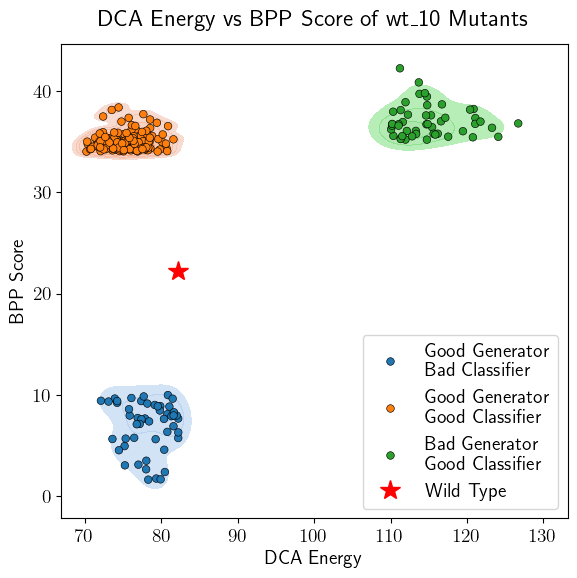

In [190]:
# create a new dataframe where the region entries are more descriptive
df_filtered_plot = df_filtered.copy()
df_filtered_plot["region"] = df_filtered_plot["region"].map({
    "lowDCA_lowSB": "Good Generator\nBad Classifier",
    "lowDCA_highSB": "Good Generator\nGood Classifier",
    "highDCA_highSB": "Bad Generator\nGood Classifier"
})
# change the column name region to Region
df_filtered_plot = df_filtered_plot.rename(columns={"region": "Region"})

# joinplot DCA energy vs BPP score with kde contours with color by region
plt.figure(figsize=(6,6))
sns.kdeplot(data=df_filtered_plot, x="dca_energy", y="bpp_score", hue="Region", fill=True, alpha=0.5)
sns.scatterplot(data=df_filtered_plot, x="dca_energy", y="bpp_score", hue="Region", s=30, edgecolor='k', alpha=1.0)

# wild type point
plt.plot(wt_energy, wt_bpp_score, 'r*', markersize=15, label="Wild Type")

plt.title(f"DCA Energy vs BPP Score of {wt_name} Mutants", y=1.02)
plt.xlabel("DCA Energy")
plt.ylabel("BPP Score")
plt.legend()
plt.tight_layout()

In [191]:
df_filtered.head()

,header,region,dca_energy,bpp_score,sequence
0,wt_10_mut_lowDCA_lowSB_beta1.25_sb-3.00_71,lowDCA_lowSB,77.398773,9.362812,UCGUACGCCGGGAAACCGCGUACGGGAUGCUGUCAAAUUCGGUGAA...
1,wt_10_mut_lowDCA_lowSB_beta1.25_sb-3.00_1085,lowDCA_lowSB,76.940582,7.695360,UCGUGCGUCGGGAAACCGUGUAAGGGAUGUUGUCAAAUUCGGUGAA...
2,wt_10_mut_lowDCA_lowSB_beta1.25_sb-3.00_615,lowDCA_lowSB,81.083344,8.821283,UCGUGCGGCGGGAAACCACUCAAGGGAUGCUGUCAAAUUCGGUGAA...
3,wt_10_mut_lowDCA_lowSB_beta1.25_sb-3.00_52,lowDCA_lowSB,77.893997,7.643451,UCGUGCGCUGGGAACCCGCGUACGGGAUGCUGUCAAAUUCGGUGAA...
4,wt_10_mut_lowDCA_lowSB_beta1.25_sb-3.00_448,lowDCA_lowSB,82.241516,5.714702,UCCUGCACCGGGAAACCAUGUAAGGGAUGUUGUCAAAUUCGGUGAA...


In [192]:
# Save results
output_dir = "../Experiment_sequences/selected_sequences"
df_filtered = df_filtered.reset_index(drop=True)
df_filtered.to_csv(os.path.join(output_dir, f"{wt_name}_mutants_selected.csv"), index=False)